# F1 : Risque de crédit en Allemagne

**Nom et prénom :** Imane Sellami    **Code Apogée :** 25007596    **Groupe :** FIN 3    **Filière :** S7 FIN    **Date :** 17/11/2026

**Dépôt GitHub :** https://github.com/IMANESELLAMI19/25007596-IMANESELLAMI-FIN3.git

## 1. Sujet et problématique
- **Intérêt du sujet** : Une banque doit décider d'accorder ou de refuser un crédit à partir du profil du client et du prêt. Accepter un mauvais payeur coûte beaucoup plus cher que refuser un bon client (coût de 5 contre 1 dans la matrice de coûts du jeu UCI). Un modèle qui estime le risque aide la banque à décider, à condition de choisir un seuil adapté à ces coûts.
- **Problématique** : Quels attributs du client et du prêt permettent d'identifier les mauvais risques, et quel seuil de décision minimise le coût total des erreurs quand accepter un mauvais risque coûte cinq fois plus que refuser un bon client ?
- **Objectif mesurable** : Métrique principale : coût total sur le jeu de test (accepter un mauvais risque = 5, refuser un bon = 1, bonne décision = 0) ; métrique secondaire : AUC. Références naïves : tout accepter et tout refuser. Jeu de test : 25 % des 1 000 dossiers, stratifié, graine 42, utilisé une seule fois. Seuil de réussite fixé avant les résultats : un coût total inférieur d'au moins 20 % à celui de la meilleure des deux références naïves, et une AUC d'au moins 0,70.
- **Nature du problème** : Classification binaire (bon ou mauvais risque), avec des classes déséquilibrées (environ 70 % de bons, 30 % de mauvais) et des coûts d'erreur asymétriques : le seuil de décision fait donc partie de la solution.
- **Algorithme principal envisagé** : n° 8, régression logistique. Elle donne une probabilité de défaut, qui permet de choisir le seuil selon les coûts, et ses coefficients sont interprétables. Je n'ai pas retenu la forêt aléatoire (n° 12) comme algorithme principal : elle est moins lisible et le jeu n'a que 1 000 lignes.

## Configuration

In [21]:
# Cloner le dépôt pour travailler avec des chemins relatifs
!git clone https://github.com/IMANESELLAMI19/25007596-IMANESELLAMI-FIN3.git
%cd /content/25007596-IMANESELLAMI-FIN3
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

GRAINE = 42
np.random.seed(GRAINE)

DATA_RAW = Path("data/raw")
FIGURES = Path("figures")          # graphiques enregistrés pour le dépôt
FIGURES.mkdir(exist_ok=True)

print("Python", sys.version.split()[0], "| pandas", pd.__version__,
      "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("Fichiers dans data/raw :", [f.name for f in DATA_RAW.iterdir()])

Cloning into '25007596-IMANESELLAMI-FIN3'...
remote: Enumerating objects: 67, done.
remote: Counting objects: 100% (67/67), done.
remote: Compressing objects: 100% (58/58), done.
remote: Total 67 (delta 22), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (67/67), 9.66 MiB | 16.34 MiB/s, done.
Resolving deltas: 100% (22/22), done.
/content/25007596-IMANESELLAMI-FIN3
Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1
Fichiers dans data/raw : ['.gitkeep', 'base_credit_allemagne (1).xlsx']


Les versions utilisées sont : Python 3.13.18, pandas 2.2.3, numpy 2.4.6 et scikit-learn 1.6.1. La graine aléatoire est fixée à 42 (`GRAINE = 42`) pour que les résultats soient reproductibles à chaque exécution. Le dépôt est cloné dans Colab, donc les chemins sont relatifs (`data/raw`), et le fichier de données y est bien présent.

## 2. Jeu de données
### Chargement et vérification

In [22]:
# Trouver automatiquement le fichier Excel dans data/raw
fichiers = list(DATA_RAW.glob("*.xlsx"))
print("Fichier trouvé :", fichiers)

df = pd.read_excel(fichiers[0])

print("Dimensions (lignes, colonnes) :", df.shape)
print("\nTypes des colonnes :")
print(df.dtypes)
print("\nValeurs manquantes par colonne :")
print(df.isna().sum())
print("\nLignes dupliquées :", df.duplicated().sum())
display(df.head())

Fichier trouvé : [PosixPath('data/raw/base_credit_allemagne (1).xlsx')]
Dimensions (lignes, colonnes) : (1000, 23)

Types des colonnes :
n°                       int64
statut_compte           object
duree_mois               int64
historique_credit       object
objet_credit            object
montant                  int64
epargne                 object
anciennete_emploi       object
taux_mensualite          int64
statut_personnel        object
autres_debiteurs        object
anciennete_residence     int64
patrimoine              object
age                      int64
autres_credits          object
logement                object
nb_credits               int64
emploi                  object
nb_personnes_charge      int64
telephone               object
travailleur_etranger    object
risque                  object
mauvais_risque (0/1)     int64
dtype: object

Valeurs manquantes par colonne :
n°                      0
statut_compte           0
duree_mois              0
historique_credit       

,n°,statut_compte,duree_mois,historique_credit,objet_credit,montant,epargne,anciennete_emploi,taux_mensualite,statut_personnel,...,age,autres_credits,logement,nb_credits,emploi,nb_personnes_charge,telephone,travailleur_etranger,risque,mauvais_risque (0/1)
0,1,< 0 DM,6,compte critique / crédits ailleurs,radio / télévision,1169,inconnue / pas d'épargne,>= 7 ans,4,homme célibataire,...,67,aucun,propriétaire,2,qualifié / fonctionnaire,1,oui,oui,bon risque,0
1,2,0 à 200 DM,48,crédits en cours remboursés normalement,radio / télévision,5951,< 100 DM,1 à 4 ans,2,femme divorcée / séparée / mariée,...,22,aucun,propriétaire,1,qualifié / fonctionnaire,1,non,oui,mauvais risque,1
2,3,pas de compte courant,12,compte critique / crédits ailleurs,études,2096,< 100 DM,4 à 7 ans,2,homme célibataire,...,49,aucun,propriétaire,1,non qualifié résident,2,non,oui,bon risque,0
3,4,< 0 DM,42,crédits en cours remboursés normalement,meubles / équipement,7882,< 100 DM,4 à 7 ans,2,homme célibataire,...,45,aucun,logé gratuitement,1,qualifié / fonctionnaire,2,non,oui,bon risque,0
4,5,< 0 DM,24,retard de paiement dans le passé,voiture neuve,4870,< 100 DM,1 à 4 ans,3,homme célibataire,...,53,aucun,logé gratuitement,2,qualifié / fonctionnaire,2,non,oui,mauvais risque,1


In [23]:
print("Colonnes :")
print(list(df.columns))

print("\nStatistiques des variables numériques :")
display(df.describe())

print("\nNombre de valeurs différentes par colonne :")
print(df.nunique())

Colonnes :
['n°', 'statut_compte', 'duree_mois', 'historique_credit', 'objet_credit', 'montant', 'epargne', 'anciennete_emploi', 'taux_mensualite', 'statut_personnel', 'autres_debiteurs', 'anciennete_residence', 'patrimoine', 'age', 'autres_credits', 'logement', 'nb_credits', 'emploi', 'nb_personnes_charge', 'telephone', 'travailleur_etranger', 'risque', 'mauvais_risque (0/1)']

Statistiques des variables numériques :


,n°,duree_mois,montant,taux_mensualite,anciennete_residence,age,nb_credits,nb_personnes_charge,mauvais_risque (0/1)
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000,0.300000
std,288.819436,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487
min,1.000000,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000,0.000000
25%,250.750000,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000,0.000000
50%,500.500000,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000,0.000000
75%,750.250000,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000,1.000000
max,1000.000000,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000,1.000000



Nombre de valeurs différentes par colonne :
n°                      1000
statut_compte              4
duree_mois                33
historique_credit          5
objet_credit              10
montant                  921
epargne                    5
anciennete_emploi          5
taux_mensualite            4
statut_personnel           4
autres_debiteurs           3
anciennete_residence       4
patrimoine                 4
age                       53
autres_credits             3
logement                   3
nb_credits                 4
emploi                     4
nb_personnes_charge        2
telephone                  2
travailleur_etranger       2
risque                     2
mauvais_risque (0/1)       2
dtype: int64


La base contient 1 000 lignes et 23 colonnes : 20 variables explicatives, un identifiant (`n°`) et deux colonnes qui décrivent la cible (`risque` en texte et `mauvais_risque (0/1)` en chiffres). Il n'y a aucune valeur manquante et aucune ligne dupliquée. Sept variables sont numériques (durée, montant, âge, etc.) et treize sont catégorielles. La moyenne de `mauvais_risque` est 0,30 : 30 % des dossiers sont des mauvais risques, donc les classes sont déséquilibrées.

### Description du jeu de données
- **Nom et source :** Statlog (German Credit Data), UCI Machine Learning Repository, dataset 144 [1]. Lien : https://archive.ics.uci.edu/dataset/144. Auteur : Hans Hofmann (1994).
- **Licence :** CC BY 4.0 (Creative Commons Attribution 4.0 International).
- **Date d'extraction :** 12/11/2026.
- **Taille :** 1 000 observations, 20 variables explicatives, plus l'identifiant `n°` et la cible en deux écritures. Pas de dimension temporelle : ce sont des dossiers de crédit sans date.
- **Unité d'observation :** une ligne correspond à un dossier de crédit d'un client d'une banque allemande.
- **Variable cible :** `mauvais_risque` (1 = mauvais risque, 0 = bon risque), construite à partir de la colonne `risque`.
- **Adéquation :** le jeu décrit le client et le prêt (durée, montant, historique de crédit, épargne, emploi, etc.) et indique si le crédit a été bien remboursé, donc il permet de répondre à la problématique.

In [24]:
# Renommer la cible pour éviter les espaces et les parenthèses
df = df.rename(columns={"mauvais_risque (0/1)": "mauvais_risque"})

print("Effectifs de la cible :")
print(df["mauvais_risque"].value_counts())
print("\nPourcentages :")
print((df["mauvais_risque"].value_counts(normalize=True) * 100).round(1))

print("\nVérification : 'risque' et 'mauvais_risque' disent-elles la même chose ?")
display(pd.crosstab(df["risque"], df["mauvais_risque"]))

Effectifs de la cible :
mauvais_risque
0    700
1    300
Name: count, dtype: int64

Pourcentages :
mauvais_risque
0    70.0
1    30.0
Name: proportion, dtype: float64

Vérification : 'risque' et 'mauvais_risque' disent-elles la même chose ?


mauvais_risque,0,1
risque,,
bon risque,700,0
mauvais risque,0,300


La variable cible est `mauvais_risque` (1 = mauvais risque, 0 = bon risque) : on compte 700 bons et 300 mauvais risques, soit 30 % de mauvais risques, donc des classes déséquilibrées. La colonne `risque` contient exactement la même information sous forme de texte, et `n°` n'est qu'un identifiant : je les exclurai des variables explicatives pour éviter une fuite de données, car une variable qui contient la cible rendrait les résultats faussement excellents.

### Dictionnaire des principales variables

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
| --- | --- | --- | --- | --- | --- |
| `mauvais_risque` | 1 si le crédit est un mauvais risque, 0 si bon risque | numérique (0/1) | sans unité | cible | 0 |
| `duree_mois` | durée du crédit | numérique | mois | explicative | 0 |
| `montant` | montant du crédit | numérique | DM (marks allemands) | explicative | 0 |
| `age` | âge du client | numérique | années | explicative | 0 |
| `taux_mensualite` | poids de la mensualité dans le revenu disponible | numérique (1 à 4) | échelle ordinale | explicative | 0 |
| `statut_compte` | situation du compte courant | catégorielle (4 modalités) | DM | explicative | 0 |
| `historique_credit` | historique de remboursement | catégorielle (5 modalités) | sans unité | explicative | 0 |
| `epargne` | niveau d'épargne | catégorielle (5 modalités) | DM | explicative | 0 |
| `n°`, `risque` | identifiant, et cible écrite en texte | identifiant, texte | sans unité | exclues du modèle | 0 |

### Limites du jeu de données
- **Ancienneté :** le jeu date de 1994 et les montants sont en marks allemands (DM) : les résultats ne se transposent pas tels quels à un portefeuille actuel.
- **Petite taille :** seulement 1 000 dossiers, dont 300 mauvais risques : l'incertitude sur les scores sera importante.
- **Déséquilibre des classes :** 30 % de mauvais risques, ce qui rend l'exactitude (accuracy) trompeuse.
- **Biais de sélection possible :** on ne connaît que les clients à qui la banque a accordé un crédit ; on n'observe pas ceux qu'elle a refusés.
- **Variables sensibles :** `statut_personnel` (qui mélange situation familiale et sexe), `age` et `travailleur_etranger` posent un risque de discrimination si le modèle servait réellement à décider.
- **Pas de dimension temporelle :** les dossiers ne sont pas datés, donc un découpage aléatoire stratifié est possible.
- **Matrice de coûts :** les coûts (5 et 1) sont une hypothèse du jeu UCI, qui détermine le seuil de décision optimal.

## 3. Exploration
### Qualité des données

In [25]:
# Détection des valeurs atypiques par la règle de l'écart interquartile (IQR)
for col in ["duree_mois", "montant", "age"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    borne_basse = q1 - 1.5 * iqr
    borne_haute = q3 + 1.5 * iqr
    nb = ((df[col] < borne_basse) | (df[col] > borne_haute)).sum()
    print(f"{col} : bornes [{borne_basse:.0f} ; {borne_haute:.0f}] | "
          f"min = {df[col].min()}, max = {df[col].max()} | valeurs atypiques : {nb}")

duree_mois : bornes [-6 ; 42] | min = 4, max = 72 | valeurs atypiques : 70
montant : bornes [-2545 ; 7882] | min = 250, max = 18424 | valeurs atypiques : 72
age : bornes [4 ; 64] | min = 19, max = 75 | valeurs atypiques : 23


**Valeurs manquantes :** aucune (0 dans toutes les colonnes). Aucune imputation n'est nécessaire.

**Doublons :** aucune ligne dupliquée. Rien à supprimer.

**Valeurs atypiques :** détectées par la règle de l'écart interquartile (IQR) : une valeur est atypique si elle est hors de [Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR].
- `duree_mois` : bornes [-6 ; 42], maximum 72 mois, 70 valeurs atypiques.
- `montant` : bornes [-2545 ; 7882], maximum 18 424 DM, 72 valeurs atypiques.
- `age` : bornes [4 ; 64], maximum 75 ans, 23 valeurs atypiques.

**Décision :** je conserve ces valeurs. Un crédit long (72 mois), un gros montant ou un client âgé sont des dossiers réels, pas des erreurs de saisie, et ce sont justement les dossiers où le risque peut être différent. Les supprimer retirerait de l'information utile et fausserait la population de clients que la banque rencontre. Pour limiter leur influence sur le modèle, je standardiserai les variables numériques à l'étape de préparation.

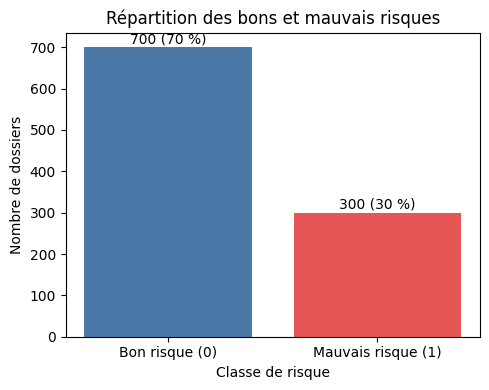

In [26]:
effectifs = df["mauvais_risque"].value_counts().sort_index()

plt.figure(figsize=(5, 4))
plt.bar(["Bon risque (0)", "Mauvais risque (1)"], effectifs.values, color=["#4c78a8", "#e45756"])
for i, v in enumerate(effectifs.values):
    plt.text(i, v + 10, f"{v} ({v / len(df) * 100:.0f} %)", ha="center")
plt.title("Répartition des bons et mauvais risques")
plt.xlabel("Classe de risque")
plt.ylabel("Nombre de dossiers")
plt.tight_layout()
plt.savefig(FIGURES / "fig1_repartition.png", dpi=200, bbox_inches="tight"); plt.show()

Le graphique montre 700 bons risques (70 %) contre 300 mauvais risques (30 %) : les classes sont déséquilibrées. Conséquence : un modèle qui accepterait tous les dossiers aurait 70 % d'exactitude sans rien apprendre, donc l'exactitude (accuracy) est une métrique trompeuse ici. J'utiliserai plutôt le coût total et l'AUC, avec comme références naïves « tout accepter » et « tout refuser », et je stratifierai le découpage pour garder 30 % de mauvais risques dans chaque jeu.

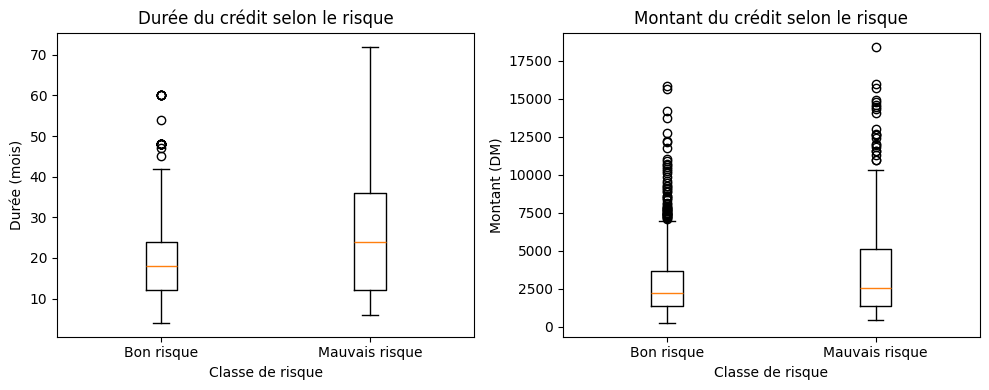

Médianes par classe :
                duree_mois  montant
mauvais_risque                     
0                     18.0   2244.0
1                     24.0   2574.5


In [27]:
bons = df[df["mauvais_risque"] == 0]
mauvais = df[df["mauvais_risque"] == 1]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].boxplot([bons["duree_mois"], mauvais["duree_mois"]])
axes[0].set_xticks([1, 2])
axes[0].set_xticklabels(["Bon risque", "Mauvais risque"])
axes[0].set_title("Durée du crédit selon le risque")
axes[0].set_xlabel("Classe de risque")
axes[0].set_ylabel("Durée (mois)")

axes[1].boxplot([bons["montant"], mauvais["montant"]])
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["Bon risque", "Mauvais risque"])
axes[1].set_title("Montant du crédit selon le risque")
axes[1].set_xlabel("Classe de risque")
axes[1].set_ylabel("Montant (DM)")

plt.tight_layout()
plt.savefig(FIGURES / "fig2_duree_montant.png", dpi=200, bbox_inches="tight"); plt.show()

print("Médianes par classe :")
print(df.groupby("mauvais_risque")[["duree_mois", "montant"]].median())

Les mauvais risques ont en médiane des crédits plus longs (24 mois contre 18 pour les bons risques) et plus élevés (2 574,5 DM contre 2 244 DM). Dans le boxplot de la durée, la boîte des mauvais risques est plus haute et ses moustaches montent jusqu'à 72 mois. Pour le montant, la différence des médianes est plus faible et les deux distributions se chevauchent beaucoup, avec de nombreuses valeurs élevées dans les deux groupes. La durée semble donc plus discriminante que le montant. Il s'agit d'une association, pas d'une preuve de causalité. Ces deux variables seront utiles au modèle, et je conserve leurs valeurs atypiques (décision prise dans la partie « Qualité des données » de la section 3).

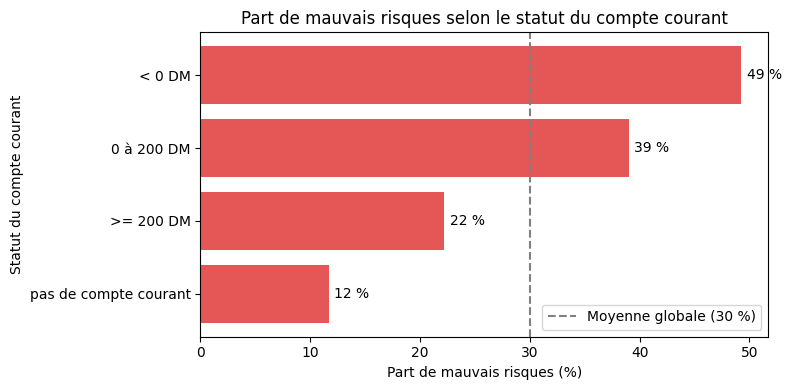

In [28]:
taux = (df.groupby("statut_compte")["mauvais_risque"].mean() * 100).sort_values()

plt.figure(figsize=(8, 4))
plt.barh(taux.index, taux.values, color="#e45756")
for i, v in enumerate(taux.values):
    plt.text(v + 0.5, i, f"{v:.0f} %", va="center")
plt.axvline(30, color="gray", linestyle="--", label="Moyenne globale (30 %)")
plt.title("Part de mauvais risques selon le statut du compte courant")
plt.xlabel("Part de mauvais risques (%)")
plt.ylabel("Statut du compte courant")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "fig3_statut_compte.png", dpi=200, bbox_inches="tight"); plt.show()

La part de mauvais risques varie fortement selon le statut du compte courant : 49 % pour les comptes à solde négatif (< 0 DM), 39 % pour 0 à 200 DM, 22 % pour 200 DM ou plus et seulement 12 % pour les clients sans compte courant, contre 30 % en moyenne. Les deux premières situations sont au-dessus de la moyenne, les deux dernières en dessous. `statut_compte` sépare donc bien les bons des mauvais clients et sera probablement une variable très informative pour le modèle. Le faible taux des clients sans compte courant est surprenant : je n'en déduis pas de cause, je constate seulement une association dans ces données.

## 4. Préparation

In [29]:
# Exclure l'identifiant et les deux écritures de la cible (fuite de données)
y = df["mauvais_risque"]
X = df.drop(columns=["n°", "risque", "mauvais_risque"])

colonnes_num = X.select_dtypes(include="number").columns.tolist()
colonnes_cat = X.select_dtypes(exclude="number").columns.tolist()
print("Variables numériques  :", len(colonnes_num), colonnes_num)
print("Variables catégorielles :", len(colonnes_cat))

# Découpage 75 % apprentissage / 25 % test, stratifié sur la cible
from sklearn.model_selection import train_test_split
X_ent, X_test, y_ent, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=GRAINE)

print("\nApprentissage :", X_ent.shape, "| Test :", X_test.shape)
print("Part de mauvais risques : apprentissage =", round(y_ent.mean(), 3),
      "| test =", round(y_test.mean(), 3))

Variables numériques  : 7 ['duree_mois', 'montant', 'taux_mensualite', 'anciennete_residence', 'age', 'nb_credits', 'nb_personnes_charge']
Variables catégorielles : 13

Apprentissage : (750, 20) | Test : (250, 20)
Part de mauvais risques : apprentissage = 0.3 | test = 0.3


J'ai retiré de X l'identifiant `n°` et les deux colonnes qui contiennent la cible (`risque` et `mauvais_risque`) pour éviter toute fuite de données. Il reste 20 variables explicatives : 7 numériques et 13 catégorielles. Les données ne sont pas datées, donc un découpage aléatoire est acceptable. Je le stratifie sur la cible : 75 % pour l'apprentissage (750 dossiers) et 25 % pour le test (250 dossiers), avec la même proportion d'environ 30 % de mauvais risques dans chaque jeu. Le jeu de test ne sera utilisé qu'une seule fois, à la fin.

### Pipeline de préparation

In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preparation = ColumnTransformer([
    ("num", StandardScaler(), colonnes_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), colonnes_cat),
])

# Ajustement (fit) sur l'apprentissage seulement, puis transformation du test
X_ent_prep = preparation.fit_transform(X_ent)
X_test_prep = preparation.transform(X_test)

print("Apprentissage après préparation :", X_ent_prep.shape)
print("Test après préparation          :", X_test_prep.shape)

# Contrôle : les variables numériques de l'apprentissage ont une moyenne de 0 et un écart-type de 1
num_ent = preparation.named_transformers_["num"].transform(X_ent[colonnes_num])
print("\nMoyenne des variables numériques (apprentissage) :", num_ent.mean(axis=0).round(2))
print("Écart-type (apprentissage)                      :", num_ent.std(axis=0).round(2))

Apprentissage après préparation : (750, 61)
Test après préparation          : (250, 61)

Moyenne des variables numériques (apprentissage) : [ 0. -0.  0. -0. -0.  0. -0.]
Écart-type (apprentissage)                      : [1. 1. 1. 1. 1. 1. 1.]


Je standardise les 7 variables numériques (moyenne 0, écart-type 1) et j'encode les 13 variables catégorielles en colonnes 0/1 (one-hot). La mise à l'échelle est nécessaire car la régression logistique est sensible à l'échelle des variables : sans elle, `montant` (jusqu'à 18 424 DM) dominerait `taux_mensualite` (de 1 à 4), et la pénalisation serait déséquilibrée. Le one-hot est nécessaire car le modèle ne sait pas traiter du texte. Toutes ces transformations sont ajustées (`fit`) sur l'apprentissage seulement, puis appliquées (`transform`) au test, pour que le test n'influence pas la préparation (pas de fuite de données). Après préparation, chaque jeu compte 61 colonnes. Je conserve les valeurs atypiques, qui sont de vrais dossiers. Cette préparation sert ici à vérifier les dimensions. Pour la modélisation (section 6), le même traitement sera placé dans un Pipeline avec le modèle, pour être recalculé dans chaque pli de validation croisée, sans fuite de données.

### Prévention des fuites de données

- ✔ Transformations (standardisation, one-hot) ajustées sur l'apprentissage seulement, dans un `Pipeline` réajusté dans chaque pli de validation croisée.
- Sans objet : découpage chronologique (dossiers non datés) ; le découpage aléatoire est stratifié, graine 42.
- Sans objet : variables construites avec le passé seulement (aucune variable créée, pas d'horizon de prévision).
- ✔ Aucune variable ne contient la cible : `n°` et `risque` sont retirées de X.
- ✔ Jeu de test utilisé une seule fois, à la fin (section 7) ; C et le seuil sont choisis en validation.

## 5. Algorithme

**Choix : régression logistique (n° 8).** La tâche est une classification binaire. Le modèle donne une probabilité de défaut, ce qui permet de fixer un seuil selon les coûts (5 contre 1). Ses coefficients sont aussi interprétables, ce qui compte pour une banque. J'écarte la forêt aléatoire (n° 12) : elle est moins lisible et le jeu ne compte que 1 000 dossiers, avec un risque de surapprentissage.

**Principe.** Le modèle calcule un score linéaire z = b + w₁x₁ + … + w_p x_p, puis le transforme en probabilité par la fonction sigmoïde :

P(y = 1 | x) = 1 / (1 + e^(−z))

- x : les variables du dossier après préparation (61 colonnes)
- w : les coefficients, un par variable
- b : l'intercept
- y = 1 : mauvais risque

Les paramètres b et w sont **appris** en minimisant la perte logarithmique (log-loss) avec une pénalité L2 qui limite la taille des coefficients (implémentation `LogisticRegression` de scikit-learn [2]). Un coefficient positif augmente la probabilité de défaut. Un coefficient négatif la diminue.

**Hyperparamètres (fixés avant l'apprentissage, non appris) :**
- `C` : inverse de la force de régularisation. Un C petit donne des coefficients contraints (modèle simple, risque de sous-apprentissage). Un C grand donne un modèle plus flexible (risque de surapprentissage). C'est l'hyperparamètre que je règle.
- Le **seuil de décision** s : on refuse le dossier si P(y = 1 | x) ≥ s. Il n'est pas appris par l'algorithme, je le choisis selon la matrice de coûts.

**Seuil théorique.** Accepter un dossier coûte 5 × P (si c'est un mauvais risque). Refuser coûte 1 × (1 − P) (si c'est un bon client). Il faut donc refuser dès que 1 − P < 5P, c'est-à-dire P > 1/6 ≈ 0,17. Ce seuil n'est exact que si les probabilités sont bien calibrées. Je vérifierai donc le seuil empiriquement en validation.

## 6. Protocole expérimental

- **Découpage :** 75 % apprentissage (750 dossiers) et 25 % test (250), stratifié, graine 42. Le test n'est utilisé qu'une seule fois, en section 7.
- **Références naïves :** « tout accepter » (aucun refus) et « tout refuser ».
- **Validation :** validation croisée stratifiée à 5 plis sur l'apprentissage. Le pipeline (standardisation + one-hot + régression logistique) est réajusté dans chaque pli.
- **Réglage :** un seul hyperparamètre, `C`, avec 6 valeurs (0,003 ; 0,01 ; 0,03 ; 0,1 ; 0,3 ; 1), soit 6 configurations. Critère : AUC moyenne en validation. L'AUC ne dépend pas du seuil, donc elle sépare le choix de C du choix du seuil.
- **Seuil :** choisi en minimisant le coût total sur les probabilités prédites hors pli (*out-of-fold*) de l'apprentissage, jamais sur le test.
- **Métriques :** principale = coût total (5 × mauvais risques acceptés + 1 × bons clients refusés). Secondaire = AUC, qui mesure la capacité à classer les dossiers risqués au-dessus des sains, sans dépendre du seuil. L'exactitude est écartée car elle est trompeuse avec 70 % de bons clients.
- **Incertitude :** moyenne et écart-type des scores sur les 5 plis.

In [31]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

COUT_MAUVAIS_ACCEPTE = 5   # mauvais risque accepté (faux négatif)
COUT_BON_REFUSE = 1        # bon client refusé (faux positif)

def cout_total(y_vrai, y_refus):
    """y_refus = 1 si on refuse le dossier, 0 si on l'accepte."""
    y_vrai, y_refus = np.asarray(y_vrai), np.asarray(y_refus)
    mauvais_acceptes = ((y_vrai == 1) & (y_refus == 0)).sum()
    bons_refuses = ((y_vrai == 0) & (y_refus == 1)).sum()
    return COUT_MAUVAIS_ACCEPTE * mauvais_acceptes + COUT_BON_REFUSE * bons_refuses

# Références naïves, évaluées sur l'apprentissage seulement
cout_accepter = cout_total(y_ent, np.zeros(len(y_ent)))
cout_refuser = cout_total(y_ent, np.ones(len(y_ent)))
print("Apprentissage - tout accepter :", cout_accepter)
print("Apprentissage - tout refuser  :", cout_refuser)

Apprentissage - tout accepter : 1125
Apprentissage - tout refuser  : 525


Sur l'apprentissage, « tout accepter » coûte 1 125 (225 mauvais risques à 5) et « tout refuser » coûte 525 (525 bons clients à 1). La meilleure référence naïve est donc « tout refuser » : c'est elle que le modèle doit battre. Le coût varie ici beaucoup moins que l'effectif, car un mauvais risque accepté pèse 5 fois plus qu'un bon client refusé.

In [32]:
# Pipeline complet (préparation + régression logistique) et validation croisée stratifiée à 5 plis
pipe = Pipeline([
    ("prep", ColumnTransformer([
        ("num", StandardScaler(), colonnes_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), colonnes_cat),
    ])),
    ("clf", LogisticRegression(max_iter=1000, random_state=GRAINE)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
print(pipe)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['duree_mois', 'montant',
                                                   'taux_mensualite',
                                                   'anciennete_residence',
                                                   'age', 'nb_credits',
                                                   'nb_personnes_charge']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['statut_compte',
                                                   'historique_credit',
                                                   'objet_credit', 'epargne',
                                                   'anciennete_emploi',
                                                   'statut_personnel',
                       

,C,AUC apprentissage,AUC validation (moy.),AUC validation (écart-type)
0,0.003,0.785,0.754,0.007
1,0.010,0.806,0.769,0.007
2,0.030,0.820,0.777,0.017
3,0.100,0.830,0.776,0.023
4,0.300,0.837,0.772,0.029
5,1.000,0.840,0.765,0.036


Meilleur C : 0.03 | 6 configurations essayées


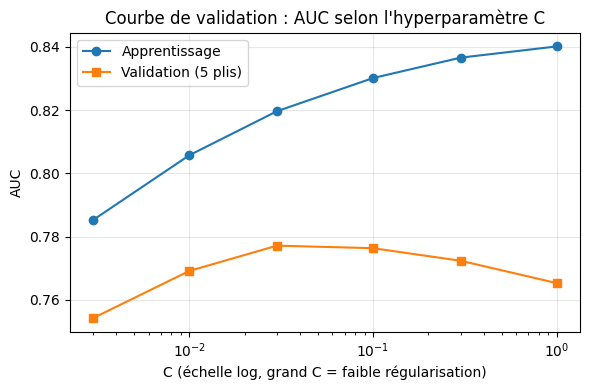

In [33]:
grille = {"clf__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1]}
gs = GridSearchCV(pipe, grille, scoring="roc_auc", cv=cv,
                  return_train_score=True).fit(X_ent, y_ent)

res = pd.DataFrame(gs.cv_results_)[["param_clf__C", "mean_train_score",
                                    "mean_test_score", "std_test_score"]]
res.columns = ["C", "AUC apprentissage", "AUC validation (moy.)", "AUC validation (écart-type)"]
display(res.round(3))
print("Meilleur C :", gs.best_params_["clf__C"], "| 6 configurations essayées")

plt.figure(figsize=(6, 4))
plt.semilogx(res["C"], res["AUC apprentissage"], "o-", label="Apprentissage")
plt.semilogx(res["C"], res["AUC validation (moy.)"], "s-", label="Validation (5 plis)")
plt.title("Courbe de validation : AUC selon l'hyperparamètre C")
plt.xlabel("C (échelle log, grand C = faible régularisation)")
plt.ylabel("AUC")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig(FIGURES / "fig6_courbe_validation.png", dpi=200, bbox_inches="tight"); plt.show()

Seuil optimal (validation) : 0.2 | coût = 385
AUC hors pli : 0.777
Coût par pli : [np.int64(81), np.int64(74), np.int64(74), np.int64(76), np.int64(80)] | moyenne 77.0 ± 3.0
AUC par pli  : moyenne 0.777 ± 0.017


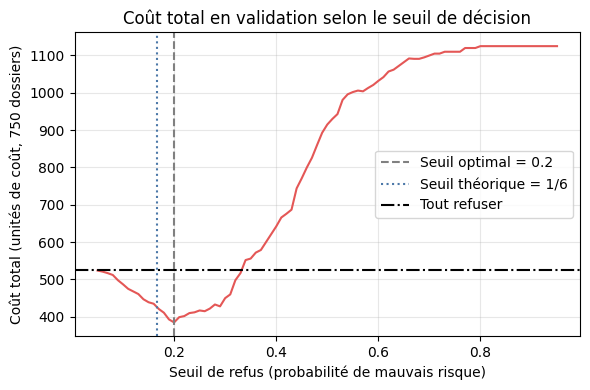

In [34]:
modele = gs.best_estimator_
proba_oof = cross_val_predict(modele, X_ent, y_ent, cv=cv, method="predict_proba")[:, 1]

seuils = np.round(np.arange(0.05, 0.96, 0.01), 2)
couts = [cout_total(y_ent, (proba_oof >= s).astype(int)) for s in seuils]
seuil_opt = seuils[int(np.argmin(couts))]
print(f"Seuil optimal (validation) : {seuil_opt} | coût = {min(couts)}")
print(f"AUC hors pli : {roc_auc_score(y_ent, proba_oof):.3f}")

# Incertitude : coût et AUC par pli au seuil retenu
c_plis, auc_plis = [], []
for tr, va in cv.split(X_ent, y_ent):
    c_plis.append(cout_total(y_ent.iloc[va], (proba_oof[va] >= seuil_opt).astype(int)))
    auc_plis.append(roc_auc_score(y_ent.iloc[va], proba_oof[va]))
print(f"Coût par pli : {c_plis} | moyenne {np.mean(c_plis):.1f} ± {np.std(c_plis):.1f}")
print(f"AUC par pli  : moyenne {np.mean(auc_plis):.3f} ± {np.std(auc_plis):.3f}")

plt.figure(figsize=(6, 4))
plt.plot(seuils, couts, color="#e45756")
plt.axvline(seuil_opt, color="gray", linestyle="--", label=f"Seuil optimal = {seuil_opt}")
plt.axvline(1/6, color="#4c78a8", linestyle=":", label="Seuil théorique = 1/6")
plt.axhline(cout_refuser, color="black", linestyle="-.", label="Tout refuser")
plt.title("Coût total en validation selon le seuil de décision")
plt.xlabel("Seuil de refus (probabilité de mauvais risque)")
plt.ylabel("Coût total (unités de coût, 750 dossiers)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig(FIGURES / "fig4_cout_seuil.png", dpi=200, bbox_inches="tight"); plt.show()

Le coût total en validation est minimal pour un seuil de 0,20 : il vaut 385, contre 525 pour « tout refuser », soit environ 27 % de moins. Ce seuil est proche du seuil théorique 1/6 ≈ 0,17, donc les probabilités du modèle sont à peu près bien calibrées. Un seuil de 0,5 serait mauvais ici : il accepterait trop de mauvais risques, qui coûtent 5 chacun. Sur les 5 plis, le coût moyen par pli (150 dossiers) est de 77,0 ± 3,0 et l'AUC moyenne de 0,777 ± 0,017 : le résultat varie d'un pli à l'autre, il faut donc rester prudent. Le seuil et C ont été choisis sans le test, qui reste intact pour la section 7.

## 7. Résultats

In [35]:
# Prédictions sur le test : le modèle (C = 0,03) a été ajusté sur l'apprentissage seulement
proba_test = modele.predict_proba(X_test)[:, 1]
refus_test = (proba_test >= seuil_opt).astype(int)

cout_modele_test = cout_total(y_test, refus_test)
cout_accepter_test = cout_total(y_test, np.zeros(len(y_test)))
cout_refuser_test = cout_total(y_test, np.ones(len(y_test)))
auc_test = roc_auc_score(y_test, proba_test)
meilleure_ref_test = min(cout_accepter_test, cout_refuser_test)
gain = (1 - cout_modele_test / meilleure_ref_test) * 100

tableau = pd.DataFrame({
    "Coût validation (750 dossiers)": [cout_accepter, cout_refuser, min(couts)],
    "Coût test (250 dossiers)": [cout_accepter_test, cout_refuser_test, cout_modele_test],
    "AUC validation": [0.5, 0.5, round(roc_auc_score(y_ent, proba_oof), 3)],
    "AUC test": [0.5, 0.5, round(auc_test, 3)],
}, index=["Tout accepter", "Tout refuser", f"Régression logistique (C={gs.best_params_['clf__C']}, seuil={seuil_opt})"])
display(tableau)

print(f"Gain du modèle sur la meilleure référence (test) : {gain:.1f} %")
print(f"Objectif 1 (coût au moins 20 % sous la meilleure référence) : {'atteint' if gain >= 20 else 'non atteint'}")
print(f"Objectif 2 (AUC test >= 0,70) : {'atteint' if auc_test >= 0.70 else 'non atteint'} ({auc_test:.3f})")

,Coût validation (750 dossiers),Coût test (250 dossiers),AUC validation,AUC test
Tout accepter,1125,375,0.500,0.500
Tout refuser,525,175,0.500,0.500
"Régression logistique (C=0.03, seuil=0.2)",385,139,0.777,0.811


Gain du modèle sur la meilleure référence (test) : 20.6 %
Objectif 1 (coût au moins 20 % sous la meilleure référence) : atteint
Objectif 2 (AUC test >= 0,70) : atteint (0.811)


Sur le test (250 dossiers), le modèle a un coût de 139, contre 175 pour « tout refuser » (meilleure référence) et 375 pour « tout accepter ». Le gain est de 20,6 %, donc l'objectif de 20 % est atteint, mais de très peu : le seuil de réussite correspondait à un coût de 140, et un seul mauvais risque accepté de plus (+5, soit un coût de 144) aurait suffi à le manquer. L'AUC test est de 0,811, au-dessus du seuil de 0,70, et même supérieure à l'AUC de validation (0,777) : l'écart-type des plis étant d'environ 0,02, cette différence reste dans l'incertitude statistique et ne montre pas de surapprentissage. Les deux objectifs sont atteints, avec une marge faible sur le coût.

Seuil 0.2 : bons acceptés = 76 | bons refusés = 99 | mauvais acceptés = 8 | mauvais refusés = 67
Coût = 5 x 8 + 1 x 99 = 139
Part de dossiers refusés : 66 % | mauvais risques détectés : 89 %


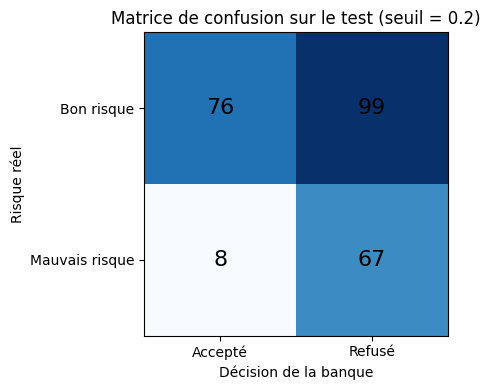


Seuil 0,5 : bons refusés = 8 | mauvais acceptés = 49 | coût = 253


,statut_compte,duree_mois,montant,age,proba_defaut
190,pas de compte courant,24,4591,54,0.12
435,0 à 200 DM,12,1484,25,0.13
228,pas de compte courant,9,1478,22,0.15
846,pas de compte courant,18,6761,68,0.15
647,pas de compte courant,12,1386,26,0.16
412,pas de compte courant,12,2292,42,0.17
598,pas de compte courant,18,2775,31,0.17
796,< 0 DM,18,7511,51,0.19


In [36]:
from sklearn.metrics import confusion_matrix

# Matrice de confusion au seuil retenu (0,20)
mc = confusion_matrix(y_test, refus_test)
tn, fp, fn, tp = mc.ravel()
print(f"Seuil {seuil_opt} : bons acceptés = {tn} | bons refusés = {fp} | "
      f"mauvais acceptés = {fn} | mauvais refusés = {tp}")
print(f"Coût = 5 x {fn} + 1 x {fp} = {5*fn + fp}")
print(f"Part de dossiers refusés : {refus_test.mean()*100:.0f} % | "
      f"mauvais risques détectés : {tp/(tp+fn)*100:.0f} %")

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(mc, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Accepté", "Refusé"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Bon risque", "Mauvais risque"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, mc[i, j], ha="center", va="center", fontsize=16)
ax.set_title(f"Matrice de confusion sur le test (seuil = {seuil_opt})")
ax.set_xlabel("Décision de la banque")
ax.set_ylabel("Risque réel")
plt.tight_layout(); plt.savefig(FIGURES / "fig5_matrice_confusion.png", dpi=200, bbox_inches="tight"); plt.show()

# Comparaison avec le seuil 0,5 (illustration seulement : le seuil retenu reste 0,20)
refus_05 = (proba_test >= 0.5).astype(int)
tn5, fp5, fn5, tp5 = confusion_matrix(y_test, refus_05).ravel()
print(f"\nSeuil 0,5 : bons refusés = {fp5} | mauvais acceptés = {fn5} | coût = {cout_total(y_test, refus_05)}")

# Les mauvais risques acceptés à tort (les erreurs les plus chères)
erreurs = X_test.copy()
erreurs["proba_defaut"] = proba_test.round(2)
erreurs["vrai_risque"] = y_test
pires = erreurs[(erreurs["vrai_risque"] == 1) & (refus_test == 0)].sort_values("proba_defaut")
display(pires[["statut_compte", "duree_mois", "montant", "age", "proba_defaut"]])

Au seuil de 0,20, le modèle refuse 166 dossiers sur 250 (66 %) et détecte 67 des 75 mauvais risques (89 %). Il commet 8 erreurs coûteuses (mauvais risques acceptés, 5 chacune, soit 40) et 99 erreurs peu coûteuses (bons clients refusés, 1 chacune, soit 99), pour un coût total de 139. Le modèle est donc très prudent : il accepte de refuser beaucoup de bons clients pour éviter les mauvais, ce qui est logique avec un rapport de coûts de 5 contre 1. À titre de comparaison, le seuil usuel de 0,5 ne refuse que 8 bons clients mais accepte 49 mauvais risques, pour un coût de 253, bien pire que « tout refuser » (175). Les 8 mauvais risques acceptés ont tous une probabilité de défaut entre 0,12 et 0,19, juste sous le seuil, et la plupart n'ont pas de compte courant, la modalité la moins risquée dans ces données (12 % de défauts, cf. section 3) : le modèle se trompe sur des profils qui paraissent sûrs. Limite pratique : refuser 66 % des demandes serait difficilement acceptable pour une vraie banque, qui devrait aussi tenir compte de la perte de clientèle.

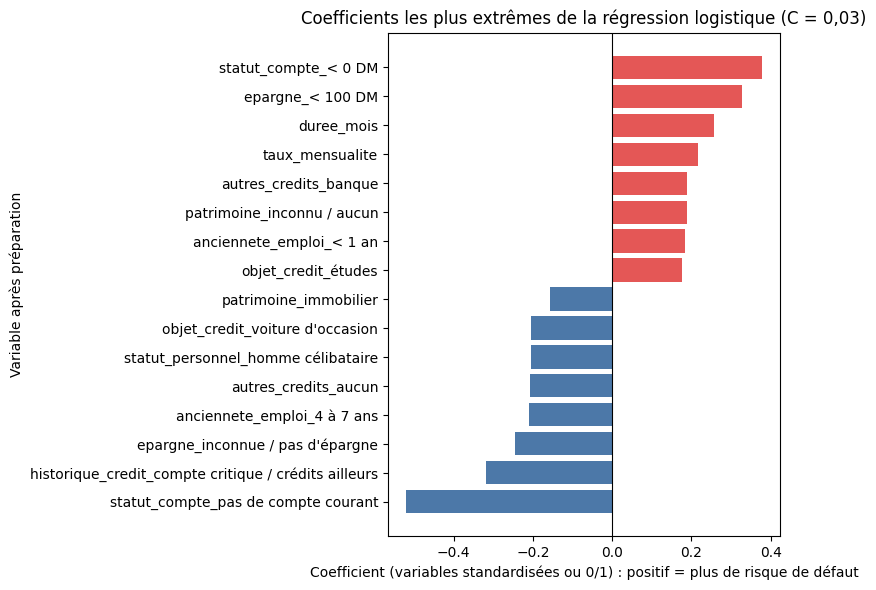

,coefficient
statut_compte_pas de compte courant,-0.52
historique_credit_compte critique / crédits ailleurs,-0.32
epargne_inconnue / pas d'épargne,-0.25
anciennete_emploi_4 à 7 ans,-0.21
autres_credits_aucun,-0.21
statut_personnel_homme célibataire,-0.21
objet_credit_voiture d'occasion,-0.20
patrimoine_immobilier,-0.16
objet_credit_études,0.18
anciennete_emploi_< 1 an,0.18


In [37]:
# Noms des 61 colonnes après préparation, et coefficients appris par la régression logistique
noms = modele.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(modele.named_steps["clf"].coef_[0], index=noms)
coefs.index = coefs.index.str.replace("num__", "", regex=False).str.replace("cat__", "", regex=False)

# Les 8 coefficients les plus négatifs et les 8 plus positifs
extremes = pd.concat([coefs.sort_values().head(8), coefs.sort_values().tail(8)])

plt.figure(figsize=(8, 6))
couleurs = ["#4c78a8" if v < 0 else "#e45756" for v in extremes.values]
plt.barh(extremes.index, extremes.values, color=couleurs)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Coefficients les plus extrêmes de la régression logistique (C = 0,03)")
plt.xlabel("Coefficient (variables standardisées ou 0/1) : positif = plus de risque de défaut")
plt.ylabel("Variable après préparation")
plt.tight_layout(); plt.savefig(FIGURES / "fig7_coefficients.png", dpi=200, bbox_inches="tight"); plt.show()

display(extremes.round(2).to_frame("coefficient"))

Les coefficients vont dans le même sens que l'exploration (section 3). Le risque augmente avec un compte courant à solde négatif (+0,38), une épargne inférieure à 100 DM (+0,33), une durée de crédit plus longue (+0,26) et un taux de mensualité plus élevé (+0,22). À l'inverse, l'absence de compte courant a le coefficient le plus négatif (−0,52), ce qui confirme le constat surprenant de la section 3 (12 % de mauvais risques seulement). Un historique « compte critique / crédits ailleurs » a aussi un coefficient négatif (−0,32), ce qui est contre-intuitif. Ces coefficients indiquent des associations dans ces données de 1994, pas des causes : par exemple, on ne peut pas conclure qu'ouvrir un compte réduit le risque. Les coefficients sont aussi réduits par la régularisation (C = 0,03) et plusieurs variables sont corrélées entre elles, donc il faut les lire comme un ordre de grandeur et non comme des effets exacts.

In [38]:
# Un dossier de chaque type (le premier rencontré dans le test), pour illustrer l'usage du modèle
y_vals = y_test.values
types = {
    "Bon client accepté (décision juste)":   (y_vals == 0) & (refus_test == 0),
    "Bon client refusé (erreur à coût 1)":   (y_vals == 0) & (refus_test == 1),
    "Mauvais risque refusé (décision juste)": (y_vals == 1) & (refus_test == 1),
    "Mauvais risque accepté (erreur à coût 5)": (y_vals == 1) & (refus_test == 0),
}

lignes = []
for nom, masque in types.items():
    i = np.where(masque)[0][0]
    d = X_test.iloc[i]
    lignes.append({
        "Cas": nom,
        "Dossier (index)": X_test.index[i],
        "Statut compte": d["statut_compte"],
        "Durée (mois)": d["duree_mois"],
        "Montant (DM)": d["montant"],
        "Âge": d["age"],
        "Épargne": d["epargne"],
        "Proba. de défaut": round(proba_test[i], 2),
        "Décision (seuil 0,20)": "Refus" if refus_test[i] == 1 else "Accord",
        "Risque réel": "Mauvais" if y_vals[i] == 1 else "Bon",
    })
display(pd.DataFrame(lignes).set_index("Cas"))

,Dossier (index),Statut compte,Durée (mois),Montant (DM),Âge,Épargne,Proba. de défaut,"Décision (seuil 0,20)",Risque réel
Cas,,,,,,,,,
Bon client accepté (décision juste),681,pas de compte courant,12,2279,37,inconnue / pas d'épargne,0.12,Accord,Bon
Bon client refusé (erreur à coût 1),455,pas de compte courant,24,2679,29,< 100 DM,0.33,Refus,Bon
Mauvais risque refusé (décision juste),522,< 0 DM,48,7119,53,< 100 DM,0.70,Refus,Mauvais
Mauvais risque accepté (erreur à coût 5),412,pas de compte courant,12,2292,42,< 100 DM,0.17,Accord,Mauvais


Ces quatre dossiers du test, non utilisés pour l'apprentissage, illustrent les quatre issues possibles. Le dossier 681 (12 mois, pas de compte courant, probabilité de défaut 0,12) est accepté et c'est un bon client : décision juste. Le dossier 522 (compte à solde négatif, 48 mois, 7 119 DM, probabilité 0,70) est refusé et c'est un mauvais risque : décision juste, avec un profil cumulant plusieurs facteurs de risque. Le dossier 455 (probabilité 0,33) est refusé alors que c'est un bon client : erreur peu coûteuse (1). Le dossier 412 (probabilité 0,17) est accepté alors que c'est un mauvais risque : erreur coûteuse (5), tombée juste sous le seuil de 0,20. Les dossiers 412 et 681 se ressemblent (même durée, même montant, pas de compte courant) mais ont des issues opposées : le modèle ne distingue pas ces cas, ce qui illustre sa limite.

AUC apprentissage = 0.817 | AUC test = 0.811


,graine,C,seuil,coût test,meilleure référence,gain (%),AUC test
0,42,0.03,0.20,139,175,20.6,0.811
1,0,0.10,0.20,131,175,25.1,0.800
2,1,0.30,0.12,127,175,27.4,0.805
3,2,0.10,0.20,141,175,19.4,0.763
4,3,0.10,0.15,137,175,21.7,0.797
5,4,0.10,0.17,147,175,16.0,0.801
6,5,0.03,0.21,149,175,14.9,0.763
7,6,0.10,0.26,152,175,13.1,0.809
8,7,0.10,0.23,131,175,25.1,0.810
9,8,0.30,0.21,178,175,-1.7,0.729


      coût test  gain (%)  AUC test
mean     143.20     18.16      0.79
std       14.75      8.41      0.03
Graines où l'objectif de 20 % est atteint : 5 sur 10
Graines où AUC >= 0,70 : 10 sur 10


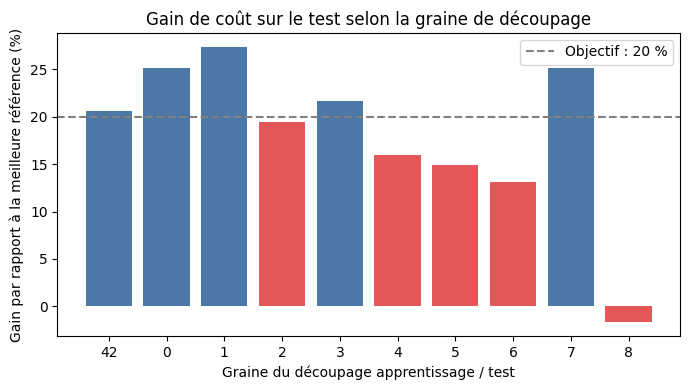

In [39]:
# 1) Surapprentissage : AUC apprentissage contre AUC test (modèle principal)
auc_ent = roc_auc_score(y_ent, modele.predict_proba(X_ent)[:, 1])
print(f"AUC apprentissage = {auc_ent:.3f} | AUC test = {auc_test:.3f}")

# 2) Stabilité : toute la démarche refaite avec 10 graines de découpage
def refaire_avec_graine(graine):
    Xe, Xt, ye, yt = train_test_split(X, y, test_size=0.25, stratify=y, random_state=graine)
    p = Pipeline([
        ("prep", ColumnTransformer([
            ("num", StandardScaler(), colonnes_num),
            ("cat", OneHotEncoder(handle_unknown="ignore"), colonnes_cat),
        ])),
        ("clf", LogisticRegression(max_iter=1000, random_state=graine)),
    ])
    cv_g = StratifiedKFold(n_splits=5, shuffle=True, random_state=graine)
    g = GridSearchCV(p, grille, scoring="roc_auc", cv=cv_g).fit(Xe, ye)
    m = g.best_estimator_
    oof = cross_val_predict(m, Xe, ye, cv=cv_g, method="predict_proba")[:, 1]
    s = seuils[int(np.argmin([cout_total(ye, (oof >= t).astype(int)) for t in seuils]))]
    pt = m.predict_proba(Xt)[:, 1]
    c = cout_total(yt, (pt >= s).astype(int))
    ref = min(cout_total(yt, np.zeros(len(yt))), cout_total(yt, np.ones(len(yt))))
    return {"graine": graine, "C": g.best_params_["clf__C"], "seuil": s,
            "coût test": c, "meilleure référence": ref,
            "gain (%)": round((1 - c / ref) * 100, 1), "AUC test": round(roc_auc_score(yt, pt), 3)}

stabilite = pd.DataFrame([refaire_avec_graine(g) for g in [42, 0, 1, 2, 3, 4, 5, 6, 7, 8]])
display(stabilite)
print(stabilite[["coût test", "gain (%)", "AUC test"]].agg(["mean", "std"]).round(2))
print("Graines où l'objectif de 20 % est atteint :", (stabilite["gain (%)"] >= 20).sum(), "sur 10")
print("Graines où AUC >= 0,70 :", (stabilite["AUC test"] >= 0.70).sum(), "sur 10")

plt.figure(figsize=(7, 4))
plt.bar(stabilite["graine"].astype(str), stabilite["gain (%)"],
        color=["#4c78a8" if g >= 20 else "#e45756" for g in stabilite["gain (%)"]])
plt.axhline(20, color="gray", linestyle="--", label="Objectif : 20 %")
plt.title("Gain de coût sur le test selon la graine de découpage")
plt.xlabel("Graine du découpage apprentissage / test")
plt.ylabel("Gain par rapport à la meilleure référence (%)")
plt.legend(); plt.tight_layout(); plt.savefig(FIGURES / "fig8_stabilite.png", dpi=200, bbox_inches="tight"); plt.show()

**Surapprentissage.** L'AUC d'apprentissage (0,817) est quasiment égale à l'AUC de test (0,811) : le modèle, fortement régularisé (C = 0,03), ne surapprend pas de façon visible.

**Stabilité.** J'ai refait toute la démarche (découpage, choix de C, choix du seuil, évaluation sur le test) avec 10 graines de découpage, dont la graine 42 retenue ; ces 9 essais supplémentaires ne servent pas à choisir le modèle, seulement à mesurer la robustesse. L'AUC test reste au-dessus de 0,70 dans les 10 cas (moyenne 0,79 ± 0,03), donc la capacité à classer les dossiers est stable. Le gain de coût est en revanche instable : en moyenne 18,2 % ± 8,4 points, et l'objectif de 20 % n'est atteint que dans 5 cas sur 10 (de −1,7 % à +27,4 %). Le résultat de la graine 42 (20,6 %) se situe donc dans le haut de la fourchette et ne doit pas être surinterprété : avec seulement 250 dossiers de test, quelques erreurs à coût 5 suffisent à modifier le gain. Le C retenu varie aussi (0,03 à 0,30) et le seuil entre 0,12 et 0,26, ce qui confirme que ces choix sont peu précis avec 750 dossiers d'apprentissage.

### Réponse à la problématique

**Quels attributs identifient les mauvais risques ?** Les coefficients du modèle (cellule précédente) et l'exploration (section 3) convergent : le risque augmente avec un compte courant à solde négatif, une épargne inférieure à 100 DM, une durée de crédit plus longue et un taux de mensualité plus élevé. Ce sont des associations observées dans ces données de 1994, pas des causes.

**Quel seuil minimise le coût ?** Le coût en validation est minimal pour un seuil de 0,20, proche du seuil théorique 1/6 ≈ 0,17 déduit du rapport de coûts de 5 contre 1. Un seuil de 0,5 donnerait un coût de 253 sur le test, supérieur à « tout refuser » (175).

**Les objectifs mesurables sont-ils atteints ?**
- Objectif 1 (coût inférieur d'au moins 20 % à la meilleure référence) : **atteint de justesse** avec la graine 42 (139 contre 175, soit 20,6 %). Le résultat n'est pas robuste : sur 10 graines de découpage, l'objectif n'est atteint que 5 fois, avec un gain moyen de 18,2 % ± 8,4 points.
- Objectif 2 (AUC d'au moins 0,70) : **atteint**, avec 0,811 sur le test, et dans les 10 découpages (moyenne 0,79 ± 0,03).

**Conclusion de la section.** Le modèle classe bien les dossiers (AUC stable autour de 0,8) et réduit le coût par rapport à une règle naïve, mais le gain de coût est modeste et incertain : environ 18 % en moyenne, avec seulement 250 dossiers de test. La régression logistique avec un seuil abaissé est donc utile, mais elle ne suffit pas à affirmer qu'elle battra toujours la règle « tout refuser » de 20 %.

## 8. Analyse critique

- **Données anciennes et peu nombreuses :** le jeu date de 1994, avec des montants en marks allemands, et ne compte que 1 000 dossiers (300 mauvais risques). Les résultats ne se transposent pas tels quels à un portefeuille actuel, et l'incertitude est forte.
- **Évaluation instable :** avec 250 dossiers de test, le gain de coût varie de −1,7 % à +27,4 % selon la graine de découpage (section 7). Le résultat de la graine 42 est donc une estimation parmi d'autres, pas une valeur fiable.
- **Biais de sélection :** seuls les clients qui ont reçu un crédit sont observés. Le modèle n'a jamais vu les dossiers refusés par la banque, donc il peut mal évaluer ce type de profil.
- **Matrice de coûts supposée :** le rapport 5 contre 1 vient du jeu UCI. Il détermine entièrement le seuil, et un autre rapport donnerait une autre décision.
- **Politique peu réaliste :** le modèle refuse 66 % des demandes au seuil 0,20. Une banque réelle perdrait des clients et du revenu d'intérêts, ce que le coût de 1 ne mesure pas.
- **Variables sensibles :** `age`, `statut_personnel` (qui mélange situation familiale et sexe) et `travailleur_etranger` sont dans le modèle. Les utiliser pour décider d'un crédit poserait un risque de discrimination.
- **Pistes d'amélioration concrètes :** (1) évaluer par validation croisée répétée ou par bootstrap pour obtenir un intervalle sur le coût ; (2) vérifier la calibration des probabilités (`CalibratedClassifierCV`) avant d'utiliser le seuil théorique 1/6 ; (3) comparer avec une forêt aléatoire ou un gradient boosting ; (4) retirer les variables sensibles et mesurer la perte de performance ; (5) tester d'autres rapports de coûts.

## 9. Conclusion

La régression logistique permet de classer les dossiers de façon stable (AUC test de 0,811, et au moins 0,70 dans les 10 découpages), et les variables les plus liées au risque sont le solde du compte courant, l'épargne, la durée et le taux de mensualité. Le seuil de décision qui minimise le coût est proche de 0,20, voisin du seuil théorique 1/6. Sur le test (graine 42), le coût est de 139 contre 175 pour « tout refuser », soit un gain de 20,6 % : l'objectif de 20 % est atteint, mais de justesse, et il ne l'est que dans 5 découpages sur 10 (gain moyen 18,2 %). La réponse à la problématique est donc : oui, un seuil abaissé réduit le coût par rapport aux règles naïves, mais le gain est modeste et incertain avec ce jeu de 1 000 dossiers.

## 10. Références et reproduction

**Références**
1. Hofmann, H. (1994). *Statlog (German Credit Data)*. UCI Machine Learning Repository, dataset 144. https://archive.ics.uci.edu/dataset/144 (licence CC BY 4.0, extraction du 12/11/2026).
2. Documentation de scikit-learn : `LogisticRegression`, `Pipeline`, `ColumnTransformer`, `GridSearchCV`, `StratifiedKFold`, `cross_val_predict`. https://scikit-learn.org/stable/
3. Support de cours `Tp_ML.ipynb` (algorithme n° 8, régression logistique) et énoncé de l'examen (sujet F1).

**Reproduction**
1. Cloner le dépôt : https://github.com/IMANESELLAMI19/25007596-IMANESELLAMI-FIN3.git
2. Installer les dépendances : `pip install -r requirements.txt` (Python 3.10 ou plus récent).
3. Ouvrir `notebooks/projet_F1.ipynb`, puis « Redémarrer et tout exécuter ». Les données sont dans `data/raw/` et toutes les graines sont fixées à 42 (la section 7 utilise en plus les graines 0 à 8 pour la stabilité).

| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
| --- | --- | --- | --- | --- |
| Claude (Anthropic) | 17/11/2026 et 24/11/2026 | Aide à la réalisation du projet (17/11) ; relecture et détection d'erreurs (24/11) | Notebook, sections 1 à 9 | Résultats relancés, code relu et compris |